In [149]:
%%capture
import numpy as np
import pandas as pd
import os
from matplotlib import pyplot as plt
!pip install qiskit-finance
!pip install qiskit_algorithms
from qiskit_finance.applications.optimization import PortfolioOptimization
from qiskit.circuit.library import TwoLocal
from qiskit.algorithms.optimizers import COBYLA
from qiskit_optimization.algorithms import MinimumEigenOptimizer
from qiskit.result import QuasiDistribution
from qiskit.primitives import Sampler
from qiskit_algorithms import SamplingVQE
from qiskit_algorithms.utils import algorithm_globals
from qiskit_algorithms import NumPyMinimumEigensolver
from qiskit_algorithms import QAOA

In [150]:
# Set the directory path to the algorithmic data
directory = r'C:\Users\Peter\PycharmProjects\Quantum_Portfolio_Optimization\algo_data'

# List the file names in the directory
algo_list = os.listdir(directory)

# Rename all algorithms for numeric ordering
# for i, f in enumerate(algo_list):
#     algo_name = f"algo{i+1}.csv"
#     os.rename(os.path.join(directory, f), os.path.join(directory, algo_name))

In [151]:
# loop to store all the dataframes
algo_dfs = []
for i in range(len(algo_list)):
    df = pd.read_csv(os.path.join(directory, algo_list[i]))
    algo_dfs.append(df)

In [152]:
# Data manipulation and storing

# Converting the trade data to datetime format
def convert_to_datetime(algo_dfs):
    for i in range(len(algo_dfs)):
        algo_dfs[i]['Open time'] = pd.to_datetime(algo_dfs[i]['Open time'], format='%d.%m.%Y %H:%M:%S')
        algo_dfs[i]['Close time'] = pd.to_datetime(algo_dfs[i]['Close time'], format='%d.%m.%Y %H:%M:%S')

# Create a new Column tracking the monthly gain per algorithm
def add_monthly_progress(algo_dfs):
    for i in range(len(algo_dfs)):
        algo_dfs[i]['Monthly Progress'] = algo_dfs[i]['Close time'].dt.to_period('M')
    

In [153]:
# Create a matrix storing the monthly progress for each algorithm
def create_monthly_progress_matrix(algo_dfs):
    # Create a new dataframe to store the monthly progress matrix
    df_matrix = pd.DataFrame()
    
    # Calculate monthly and cumulative pnl for each algorithm
    for i in range(len(algo_dfs)):
        monthly_pnl = algo_dfs[i].groupby('Monthly Progress')['P/L in money'].sum()
        cumulative_pnl = monthly_pnl.cumsum()
        
        # Add the monthly cumulative % pnl to the dataframe
        cumulative_percentage_pnl = (cumulative_pnl / 10000) * 100
        df_matrix[i] = (cumulative_percentage_pnl)
        
        # Convert the dataframe to a numpy array
        dfa_matrix = df_matrix.to_numpy()
        
    return dfa_matrix
    

In [154]:
# Data cleaning
def clean_data(dfa_matrix):
    for i in range(1, dfa_matrix.shape[1]):
        # Find the indices of NaN values
        nan_indices = np.isnan(dfa_matrix[:, i])
        # Find the indices of the previous non-NaN values
        previous_value_indices = np.where(~nan_indices, dfa_matrix[:, i], dfa_matrix[:, i-1])
        # Forward-fill the NaN values
        dfa_matrix[nan_indices, i] = previous_value_indices[nan_indices]
        
    return dfa_matrix
    

In [155]:
# Call functions
convert_to_datetime(algo_dfs)
add_monthly_progress(algo_dfs)
dfa_matrix = create_monthly_progress_matrix(algo_dfs)
dfa_matrix = clean_data(dfa_matrix)

In [156]:
cov = np.cov(dfa_matrix[:10])
mean  = [np.mean(dfa_matrix[x]) for x in range(len(dfa_matrix[:10]))]

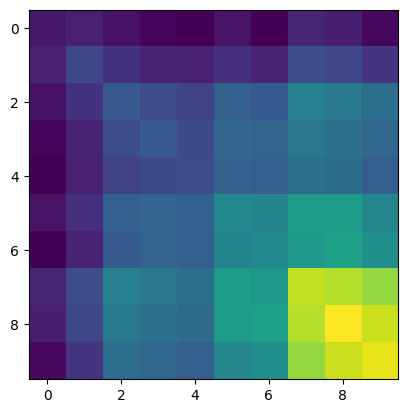

In [157]:
plt.imshow(cov, interpolation='nearest')
plt.show()

In [158]:
# Parameters for portfolio optimizer
num_assets = 10
risk_factor = 0.95
budget = 5

# Create the portfolio optimization object
portfolio = PortfolioOptimization(expected_returns = mean, covariances = cov, risk_factor = risk_factor, budget = budget)

# Transform the portfolio to a quadratic program
qp = portfolio.to_quadratic_program()

In [159]:
# Custom style to display limited information of the result
def print_result(result, limit=5):
    selection = result.x
    value = result.fval
    print("Optimal: selection {}, value {:.4f}".format(selection, value))

    eigenstate = result.min_eigen_solver_result.eigenstate
    probabilities = (
        eigenstate.binary_probabilities()
        if isinstance(eigenstate, QuasiDistribution)
        else {k: np.abs(v) ** 2 for k, v in eigenstate.to_dict().items()}
    )
    print("\n----------------- Top {} Results ---------------------".format(limit))
    print("selection\tvalue\t\tprobability")
    print("---------------------------------------------------")
    probabilities = sorted(probabilities.items(), key=lambda x: x[1], reverse=True)

    # Display only the top 'limit' results
    for i, (k, v) in enumerate(probabilities):
        if i >= limit:
            break
        x = np.array([int(i) for i in list(reversed(k))])
        value = portfolio.to_quadratic_program().objective.evaluate(x)
        print("%10s\t%.10f\t\t%.10f" % (x, value, v))

In [160]:
# Classical approach to find the optimal portfolio

# Initialize the Sampling Classical Eigensolver
sce_mes = NumPyMinimumEigensolver()

# Find the minimum eigenvalue of the Hamiltonian
sce = MinimumEigenOptimizer(sce_mes)

# Solve the classical optimization problem using the sce optimizer by passing in the quadratic problem
result = sce.solve(qp)

print_result(result, limit=5)  # Display top 5 configurations

Optimal: selection [1. 1. 1. 1. 1. 0. 0. 0. 0. 0.], value 55.9725

----------------- Top 5 Results ---------------------
selection	value		probability
---------------------------------------------------
[1 1 1 1 1 0 0 0 0 0]	55.9724635081		1.0000000000


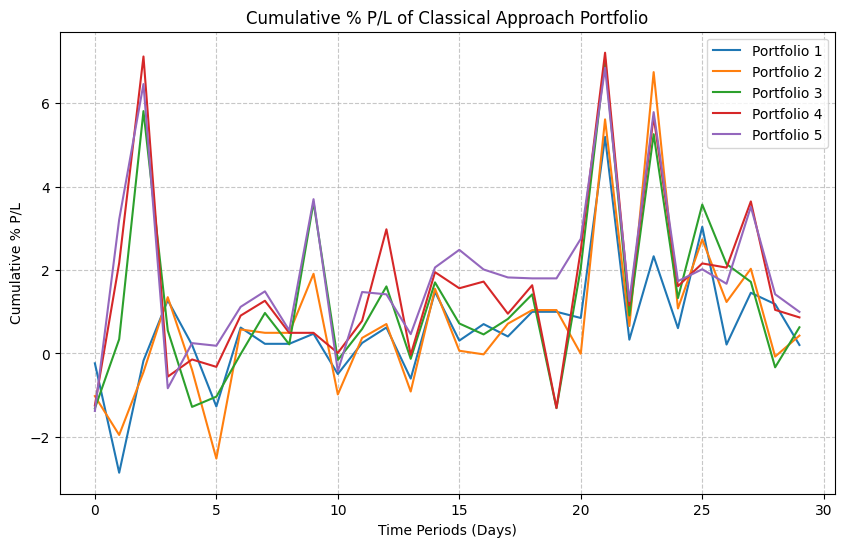

In [166]:
# Plot the cumulative % P/L of the Classical approach
plt.figure(figsize=(10, 6))

# Plot each line
plt.plot(dfa_matrix[0], label="Portfolio 1")
plt.plot(dfa_matrix[1], label="Portfolio 2")
plt.plot(dfa_matrix[2], label="Portfolio 3")
plt.plot(dfa_matrix[3], label="Portfolio 4")
plt.plot(dfa_matrix[4], label="Portfolio 5")

# Title and labels
plt.title("Cumulative % P/L of Classical Approach Portfolio")
plt.xlabel("Time Periods (Days)")
plt.ylabel("Cumulative % P/L")
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend(loc="best")
plt.show()

In [167]:
# Quantum approach to find the optimal portfolio using VQE

# Sets the random seed
algorithm_globals.random_seed = 1234

# Initialize the classical COBYLA optimizer with a set number of iterations
cobyla = COBYLA()
cobyla.set_options(maxiter=500)

'''Define the ansatz using the TwoLocal circuit.
   The configuration uses (ry) gates and (cz) gates for entanglement,
   applied over a number of qubits equal to num_assets'''
a = TwoLocal(num_assets, "ry", "cz", reps=3, entanglement="full")

'''Initialize the Sampling Variational Quantum Eigensolver (SamplingVQE) 
   with the previously defined COBYLA optimizer and TwoLocal ansatz in order 
   to find the minimum eigenvalue of the Hamiltonian'''
svqe_mes = SamplingVQE(sampler=Sampler(), ansatz=a, optimizer=cobyla)

# Find the minimum eigenvalue of the Hamiltonian
svqe = MinimumEigenOptimizer(svqe_mes)

# Solve the quantum optimization problem using the svqe optimizer by passing in the quadratic problem
result = svqe.solve(qp)

print_result(result)

Optimal: selection [1. 1. 1. 0. 1. 0. 0. 0. 1. 0.], value 71.5262

----------------- Top 5 Results ---------------------
selection	value		probability
---------------------------------------------------
[1 0 1 0 1 0 1 0 1 0]	85.6202498009		0.3941599368
[1 1 0 0 0 1 1 0 1 0]	87.3534813854		0.3643785997
[0 1 0 1 0 1 1 0 0 1]	100.8348493199		0.1340369589
[0 0 1 1 1 0 1 0 0 1]	102.9229402905		0.1032225604
[1 0 1 0 1 1 1 0 1 0]	134.5491091093		0.0004229683


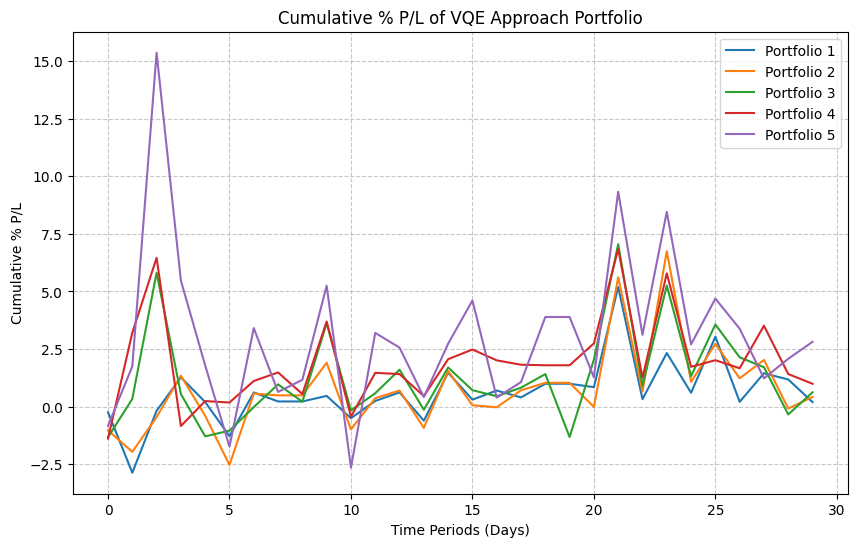

In [168]:
# Plot the cumulative % P/L of the VQE approach
plt.figure(figsize=(10, 6))

# Plot each line
plt.plot(dfa_matrix[0], label="Portfolio 1")
plt.plot(dfa_matrix[1], label="Portfolio 2")
plt.plot(dfa_matrix[2], label="Portfolio 3")
plt.plot(dfa_matrix[4], label="Portfolio 4")
plt.plot(dfa_matrix[8], label="Portfolio 5")

# Title and labels
plt.title("Cumulative % P/L of VQE Approach Portfolio")
plt.xlabel("Time Periods (Days)")
plt.ylabel("Cumulative % P/L")
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend(loc="best")
plt.show()

In [169]:
# Quantum approach to find the optimal portfolio using QAOA
# Sets the random seed
algorithm_globals.random_seed = 1234

# Initialize the classical COBYLA optimizer with a set number of iterations
cobyla = COBYLA()
cobyla.set_options(maxiter=250)

'''Initialize the Sampling Quantum Appoximation Optimization Algorithm (SamplingQAOA) 
   with the previously defined COBYLA optimizer with 3 repetition to find the minimum 
   eigenvalue of the Hamiltonian'''
qaoa_mes = QAOA(sampler=Sampler(), optimizer=cobyla, reps=3)

# Find the minimum eigenvalue of the Hamiltonian
qaoa = MinimumEigenOptimizer(qaoa_mes)

# Solve the quantum optimization problem using the qaoa optimizer by passing in the quadratic problem
result = qaoa.solve(qp)

print_result(result)

Optimal: selection [1. 1. 1. 1. 1. 0. 0. 0. 0. 0.], value 55.9725

----------------- Top 5 Results ---------------------
selection	value		probability
---------------------------------------------------
[1 1 0 0 0 1 1 1 0 0]	86.8781892751		0.0072448633
[1 1 1 0 1 0 1 1 0 0]	112.4831784839		0.0067993584
[0 1 0 1 1 1 1 0 0 0]	84.1071358245		0.0053954886
[0 1 1 0 1 1 1 0 0 1]	139.0222575007		0.0053883230
[0 1 0 0 0 0 1 0 1 1]	85.7197655826		0.0051616085


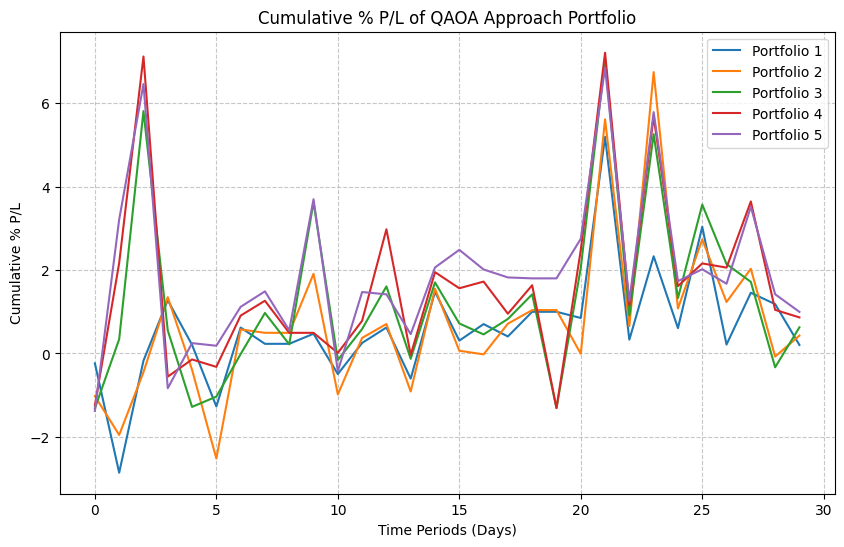

In [170]:
# Plot the cumulative % P/L of the QAOA approach
plt.figure(figsize=(10, 6))

# Plot each line
plt.plot(dfa_matrix[0], label="Portfolio 1")
plt.plot(dfa_matrix[1], label="Portfolio 2")
plt.plot(dfa_matrix[2], label="Portfolio 3")
plt.plot(dfa_matrix[3], label="Portfolio 4")
plt.plot(dfa_matrix[4], label="Portfolio 5")

# Title and labels
plt.title("Cumulative % P/L of QAOA Approach Portfolio")
plt.xlabel("Time Periods (Days)")
plt.ylabel("Cumulative % P/L")
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend(loc="best")
plt.show()